# Predicting Inorganic Fertilizer Adoption on Rwandan Farm Plots
## Notebook 3: Deep Learning (TensorFlow / Keras) and the final comparison with traditional ML

This notebook trains neural networks on **exactly the same features and the same farmer-grouped train/validation/test split** as notebook 2, so the comparison is fair.

**What is covered:**
1. Input pipelines built with the **`tf.data` API** (`from_tensor_slices → cache → shuffle → batch → prefetch`)
2. **Sequential API** models: multilayer perceptrons (MLPs)
3. **Functional API** model: a multi-input network with learned **embeddings** for district and province
4. Experiments: a deliberately overfitting baseline, architecture (depth/width), regularisation (dropout, L2, batch normalisation), optimiser / learning rate / batch size, and a **random hyperparameter search**
5. Seed-stability check, training curves, and a training-size learning curve
6. Final test evaluation and a head-to-head **traditional ML vs deep learning** comparison with bootstrap confidence intervals

As in notebook 2, all choices are made on the **validation** set. The **test** set is used once, in Section 9.

### Setup

In [1]:
import os, sys, json, time, random, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # hide TensorFlow C++ info logs
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import load_model_table, add_farmer_features, build_preprocessor, FARMER_FEATURES
from src.evaluation import (set_style, metrics, best_f1_threshold, plot_confusion, plot_roc_pr,
                            plot_learning_curve, MODEL_CLR, CLASS_CLR, MUTED)

SEED = 42
FIG = ROOT / "figures"; MODELS = ROOT / "models"; RESULTS = ROOT / "results"
for p in (FIG, MODELS, RESULTS): p.mkdir(exist_ok=True)
set_style(); warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")   # hide tf.function retracing notices (harmless when training many models in a loop)

def set_seed(s=SEED):
    keras.utils.set_random_seed(s)     # seeds Python, NumPy and TensorFlow together

set_seed()
# Note: if you have no GPU, TensorFlow may print "could not find cuda drivers" messages above. They are harmless.
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU") or "none (CPU is fine for this dataset)")

I0000 00:00:1791884178.828109   15753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791884178.830178   15753 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791884180.672524   15753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791884180.673583   15753 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | GPUs: none (CPU is fine for this dataset)


E0000 00:00:1791884181.904993   15753 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### 1. Load data and preprocess
We reuse the table and split from notebook 1, the same engineered farmer features as notebook 2, and the **same `ColumnTransformer`** (one-hot categoricals, median-imputed and standardised numerics, binary flags passed through). It is fitted on the **training set only** and then applied to the validation and test sets.

Neural networks need numeric, similarly scaled inputs, so standardisation is essential here (unlike for trees). The result is a dense `float32` matrix with one column per one-hot level or feature.

In [2]:
df, spec = load_model_table(ROOT / "data" / "processed")
df = add_farmer_features(df)
TARGET = spec["target"]
CAT, NUM, BIN = spec["categorical"], spec["numeric"] + FARMER_FEATURES, spec["binary"]
FEATS = CAT + NUM + BIN
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))

pre = build_preprocessor(CAT, NUM, BIN).fit(train[FEATS])
to_dense = lambda m: np.asarray(m.toarray() if hasattr(m, "toarray") else m, dtype="float32")
X_tr, X_va, X_te = (to_dense(pre.transform(d[FEATS])) for d in (train, val, test))
y_tr, y_va, y_te = (d[TARGET].values.astype("float32") for d in (train, val, test))
N_IN = X_tr.shape[1]
print(f"X_train {X_tr.shape} | X_val {X_va.shape} | X_test {X_te.shape} | positive rate {y_tr.mean():.3f}")

X_train (23127, 92) | X_val (5056, 92) | X_test (5045, 92) | positive rate 0.277


**Class imbalance.** As in notebook 2, we use **class weights** so that each mistake on a fertilized plot costs about 1.8× as much as a mistake on an unfertilized one. Keras applies these weights to the loss during training.

In [3]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr.astype(int))
CLASS_WEIGHT = {0: float(cw[0]), 1: float(cw[1])}
print("class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

class weights: {0: 0.691, 1: 1.808}


### 2. The `tf.data` input pipeline
Instead of passing NumPy arrays straight to `model.fit`, we wrap them in a `tf.data.Dataset`:

| Step | What it does | Why |
|---|---|---|
| `from_tensor_slices((X, y))` | Turns arrays into a dataset of `(features, label)` examples | Standard entry point for in-memory data |
| `.cache()` | Keeps the examples in memory after the first pass | Avoids re-reading or re-slicing on every epoch |
| `.shuffle(buffer, seed, reshuffle_each_iteration=True)` | Randomises example order **every epoch** (training only) | Stops the network learning from row order; a buffer as large as the dataset gives a full shuffle |
| `.batch(batch_size)` | Groups examples into mini-batches | Mini-batch gradient descent |
| `.prefetch(AUTOTUNE)` | Prepares the next batch while the current one trains | Overlaps data preparation with computation |

Validation and test data are **not shuffled**, so predictions stay in row order.

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(X, y=None, batch_size=256, training=False):
    data = X if y is None else (X, y)
    ds = tf.data.Dataset.from_tensor_slices(data).cache()
    if training:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

ds_demo = make_dataset(X_tr, y_tr, batch_size=256, training=True)
print(ds_demo.element_spec)
xb, yb = next(iter(ds_demo))
print("one batch:", xb.shape, yb.shape, "| positives in batch:", int(yb.numpy().sum()))
print("batches per epoch:", ds_demo.cardinality().numpy())

(TensorSpec(shape=(None, 92), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
one batch: (256, 92) (256,) | positives in batch: 57
batches per epoch: 91


### 3. Model builder and training loop
`build_mlp` builds a **Sequential** network from a configuration dictionary, so every experiment is a change to one dictionary:

- **Hidden layers**: `Dense` with ReLU activation; optional **batch normalisation**, **dropout** and **L2 weight decay**
- **Output**: one sigmoid unit, i.e. P(fertilizer)
- **Loss**: binary cross-entropy, weighted by the class weights
- **Monitoring**: ROC-AUC on the validation set after every epoch

**Early stopping** watches validation ROC-AUC, stops after `patience` epochs without improvement, and **restores the best weights**. **ReduceLROnPlateau** halves the learning rate when validation loss stalls.

In [5]:
BASE = dict(units=(128, 64), dropout=0.3, l2=0.0, batchnorm=False, optimizer="adam",
            lr=1e-3, batch_size=256, epochs=150, patience=12, early_stopping=True)

def build_mlp(cfg, n_in=N_IN):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] else None
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(n_in,)))
    for u in cfg["units"]:
        model.add(layers.Dense(u, kernel_regularizer=reg, use_bias=not cfg["batchnorm"]))
        if cfg["batchnorm"]: model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if cfg["dropout"]: model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

def make_optimizer(cfg):
    return {"adam": keras.optimizers.Adam(cfg["lr"]),
            "sgd": keras.optimizers.SGD(cfg["lr"], momentum=0.9, nesterov=True),
            "rmsprop": keras.optimizers.RMSprop(cfg["lr"])}[cfg["optimizer"]]

def train_model(cfg, build=build_mlp, data=None, seed=SEED, verbose=0):
    """Build, compile and train a model from a config. Returns (model, history, info)."""
    set_seed(seed)
    Xt, yt, Xv, yv = data or (X_tr, y_tr, X_va, y_va)
    model = build(cfg)
    model.compile(optimizer=make_optimizer(cfg), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(name="pr_auc", curve="PR")])
    cbs = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)]
    if cfg["early_stopping"]:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=cfg["patience"],
                                                 restore_best_weights=True))
    t = time.time()
    hist = model.fit(make_dataset(Xt, yt, cfg["batch_size"], training=True),
                     validation_data=make_dataset(Xv, yv, 2048), epochs=cfg["epochs"],
                     class_weight=CLASS_WEIGHT, callbacks=cbs, shuffle=False, verbose=verbose)
    p = model.predict(make_dataset(Xv, batch_size=2048), verbose=0).ravel()
    info = {"val_roc_auc": roc_auc_score(yv, p), **{f"val_{k}": v for k, v in metrics(yv, p, (p >= 0.5).astype(int)).items() if k != "roc_auc"},
            "epochs_run": len(hist.history["loss"]),
            "best_epoch": int(np.argmax(hist.history["val_auc"])) + 1 if cfg["early_stopping"] else len(hist.history["loss"]),
            "params": model.count_params(), "train_seconds": time.time() - t}
    return model, hist, info

LOG = []   # every experiment run is appended here, giving a complete experiment log

def run(name, experiment, **changes):
    cfg = {**BASE, **changes}
    model, hist, info = train_model(cfg)
    LOG.append({"experiment": experiment, "run": name, **{k: cfg[k] for k in BASE}, **info})
    print(f"{name:38s} val ROC-AUC {info['val_roc_auc']:.4f} | F1 {info['val_f1']:.3f} | "
          f"epochs {info['epochs_run']:3d} (best {info['best_epoch']:3d}) | {info['params']:>7,} params | {info['train_seconds']:.0f}s")
    return model, hist, info

### 4. Experiment 1: baselines, and what overfitting looks like
Two reference points:
- **Logistic regression in Keras**: zero hidden layers, i.e. one sigmoid neuron. It should land close to scikit-learn's Logistic Regression (validation ROC-AUC about 0.880) and confirms the pipeline is correct.
- **A large unregularised network**: 256-128-64 units, **no dropout and no early stopping**, trained for 100 epochs. It shows what happens when a flexible model is allowed to memorise the training data.

In [6]:
_, h_lr, _ = run("Keras logistic regression (0 hidden)", "1 baseline", units=(), dropout=0.0)
_, h_over, _ = run("Large MLP, no regularisation, 100 ep", "1 baseline", units=(256, 128, 64), dropout=0.0,
                   early_stopping=False, epochs=100)
_, h_base, _ = run("Default MLP 128-64, dropout 0.3 + ES", "1 baseline")

Keras logistic regression (0 hidden)   val ROC-AUC 0.8783 | F1 0.692 | epochs  63 (best  51) |      93 params | 16s


Large MLP, no regularisation, 100 ep   val ROC-AUC 0.8688 | F1 0.687 | epochs 100 (best 100) |  65,025 params | 35s


Default MLP 128-64, dropout 0.3 + ES   val ROC-AUC 0.8996 | F1 0.708 | epochs  38 (best  26) |  20,225 params | 13s


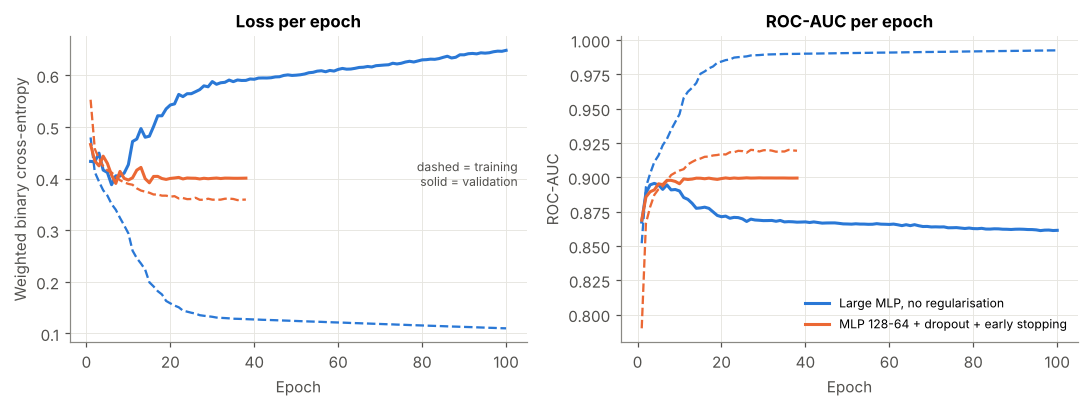

In [7]:
def plot_history(hists, fname):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for k, (name, h) in enumerate(hists.items()):
        c = MODEL_CLR[k]
        ep = np.arange(1, len(h.history["loss"]) + 1)
        axes[0].plot(ep, h.history["loss"], color=c, lw=1.5, ls="--")
        axes[0].plot(ep, h.history["val_loss"], color=c, lw=2, label=name)
        axes[1].plot(ep, h.history["auc"], color=c, lw=1.5, ls="--")
        axes[1].plot(ep, h.history["val_auc"], color=c, lw=2, label=name)
    axes[0].set(title="Loss per epoch", xlabel="Epoch", ylabel="Weighted binary cross-entropy")
    axes[1].set(title="ROC-AUC per epoch", xlabel="Epoch", ylabel="ROC-AUC")
    axes[1].legend(frameon=False, fontsize=8, loc="lower right")
    axes[0].text(0.98, 0.55, "dashed = training\nsolid = validation", transform=axes[0].transAxes,
                 ha="right", va="center", fontsize=8, color=MUTED)
    plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

plot_history({"Large MLP, no regularisation": h_over, "MLP 128-64 + dropout + early stopping": h_base},
             FIG / "14_dl_overfitting_curves.png")

> ✍️ **Your interpretation:** Look at the unregularised network. After how many epochs does the **validation loss** stop falling and start *rising*, while the training loss keeps decreasing? What happens to the gap between training and validation ROC-AUC? This is overfitting, shown in the curves. Compare it with the regularised network: how do dropout and early stopping change the picture? How did the Keras logistic regression compare with the scikit-learn one (about 0.880)?

### 5. Experiment 2: architecture (depth and width)
Holding everything else at the defaults (dropout 0.3, Adam lr = 10⁻³, batch 256, early stopping), we vary the number and size of hidden layers, from a single small layer to three wide layers.

In [8]:
for units in [(32,), (64, 32), (128, 64), (256, 128), (256, 128, 64), (512, 256, 128)]:
    run("units " + "-".join(map(str, units)), "2 architecture", units=units)

units 32                               val ROC-AUC 0.8955 | F1 0.708 | epochs 150 (best 149) |   3,009 params | 39s


units 64-32                            val ROC-AUC 0.8981 | F1 0.706 | epochs  88 (best  76) |   8,065 params | 26s


units 128-64                           val ROC-AUC 0.8996 | F1 0.708 | epochs  38 (best  26) |  20,225 params | 14s


units 256-128                          val ROC-AUC 0.8989 | F1 0.725 | epochs  19 (best   7) |  56,833 params | 11s


units 256-128-64                       val ROC-AUC 0.8994 | F1 0.722 | epochs  19 (best   7) |  65,025 params | 11s


units 512-256-128                      val ROC-AUC 0.8990 | F1 0.715 | epochs  21 (best   9) | 211,969 params | 17s


In [9]:
log = pd.DataFrame(LOG)
best_arch = log[log.experiment == "2 architecture"].sort_values("val_roc_auc", ascending=False).iloc[0]
BASE["units"] = tuple(best_arch["units"])
print("Best architecture carried forward:", BASE["units"])

Best architecture carried forward: (128, 64)


### 6. Experiment 3: regularisation
Using the best architecture, we vary **dropout rate**, **L2 weight decay** and **batch normalisation** one at a time.

In [10]:
for d in [0.0, 0.2, 0.4, 0.5]:
    run(f"dropout {d}", "3 regularisation", dropout=d)
for l2 in [1e-5, 1e-4, 1e-3]:
    run(f"dropout 0.3 + L2 {l2:g}", "3 regularisation", l2=l2)
_ = run("dropout 0.3 + batch normalisation", "3 regularisation", batchnorm=True)

dropout 0.0                            val ROC-AUC 0.8989 | F1 0.724 | epochs  19 (best   7) |  20,225 params | 6s


dropout 0.2                            val ROC-AUC 0.9007 | F1 0.712 | epochs  27 (best  15) |  20,225 params | 11s


dropout 0.4                            val ROC-AUC 0.8993 | F1 0.708 | epochs  38 (best  26) |  20,225 params | 15s


dropout 0.5                            val ROC-AUC 0.8998 | F1 0.707 | epochs  41 (best  29) |  20,225 params | 17s


dropout 0.3 + L2 1e-05                 val ROC-AUC 0.8997 | F1 0.708 | epochs  38 (best  26) |  20,225 params | 16s


dropout 0.3 + L2 0.0001                val ROC-AUC 0.9000 | F1 0.712 | epochs  38 (best  26) |  20,225 params | 17s


dropout 0.3 + L2 0.001                 val ROC-AUC 0.9000 | F1 0.716 | epochs  38 (best  26) |  20,225 params | 16s


dropout 0.3 + batch normalisation      val ROC-AUC 0.9032 | F1 0.716 | epochs  38 (best  26) |  20,801 params | 17s


### 7. Experiment 4: optimiser, learning rate and batch size

In [11]:
for opt, lr in [("adam", 3e-3), ("adam", 3e-4), ("rmsprop", 1e-3), ("sgd", 1e-2)]:
    run(f"{opt} lr={lr:g}", "4 optimisation", optimizer=opt, lr=lr)
for bs in [64, 1024]:
    run(f"adam lr=0.001, batch {bs}", "4 optimisation", batch_size=bs)

adam lr=0.003                          val ROC-AUC 0.8985 | F1 0.721 | epochs  19 (best   7) |  20,225 params | 8s


adam lr=0.0003                         val ROC-AUC 0.8969 | F1 0.703 | epochs 150 (best 150) |  20,225 params | 55s


rmsprop lr=0.001                       val ROC-AUC 0.8988 | F1 0.705 | epochs  38 (best  26) |  20,225 params | 15s


sgd lr=0.01                            val ROC-AUC 0.8949 | F1 0.704 | epochs  45 (best  33) |  20,225 params | 15s


adam lr=0.001, batch 64                val ROC-AUC 0.9003 | F1 0.712 | epochs  21 (best   9) |  20,225 params | 19s


adam lr=0.001, batch 1024              val ROC-AUC 0.8989 | F1 0.706 | epochs  52 (best  40) |  20,225 params | 13s


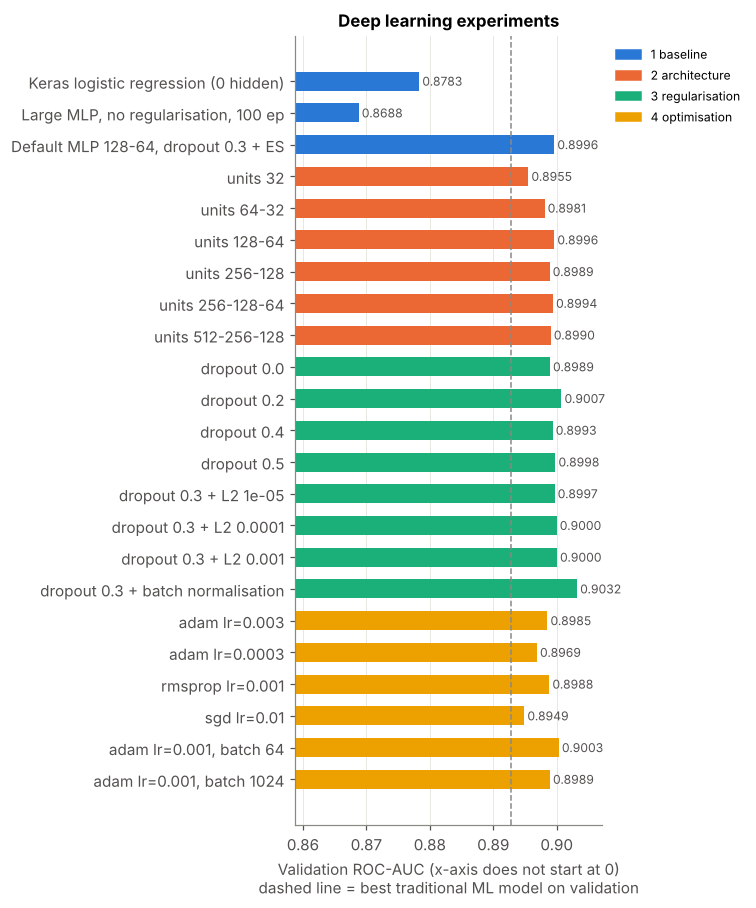

,experiment,run,val_roc_auc,val_f1,epochs_run,params
2,1 baseline,"Default MLP 128-64, dropout 0.3 + ES",0.8996,0.7076,38,20225
5,2 architecture,units 128-64,0.8996,0.7076,38,20225
16,3 regularisation,dropout 0.3 + batch normalisation,0.9032,0.7157,38,20801
21,4 optimisation,"adam lr=0.001, batch 64",0.9003,0.7116,21,20225


In [12]:
log = pd.DataFrame(LOG)
GB_VAL_AUC = max(json.load(open(RESULTS / "traditional_ml_results.json"))["val_auc_tuned"].values())  # best ML model on validation
def exp_plot(exps, fname):
    sub = log[log.experiment.isin(exps)].copy()
    sub = sub.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(sub) + 1))
    colors = [MODEL_CLR[sorted(log.experiment.unique()).index(e)] for e in sub.experiment]
    ax.barh(sub["run"], sub["val_roc_auc"], color=colors, height=0.6)
    lo = sub["val_roc_auc"].min() - 0.01
    for i, v in enumerate(sub["val_roc_auc"]):
        ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(lo, sub["val_roc_auc"].max() + 0.004)
    ax.axvline(GB_VAL_AUC, color="#8a8984", ls="--", lw=1)
    ax.set_xlabel("Validation ROC-AUC (x-axis does not start at 0)\ndashed line = best traditional ML model on validation")
    ax.set_title("Deep learning experiments")
    ax.grid(axis="y", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_CLR[sorted(log.experiment.unique()).index(e)]) for e in exps]
    ax.legend(handles, exps, frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

exp_plot(["1 baseline", "2 architecture", "3 regularisation", "4 optimisation"], FIG / "15_dl_experiments.png")
log.sort_values("val_roc_auc", ascending=False).groupby("experiment").head(1).sort_values("experiment")[["experiment", "run", "val_roc_auc", "val_f1", "epochs_run", "params"]].round(4)

> you can see the bigger network did not help and Protection against overfitting is essential (0.869 without it vs 0.900 with it), but once early stopping is used, the exact amount of dropout makes little difference. Batch normalisation gave a small extra gain.

### 8. Experiment 5: random hyperparameter search
One-factor-at-a-time experiments miss *interactions* (e.g. a larger network may need more dropout). We therefore run a **random search** of 15 configurations drawn jointly from the space below and pick the best one on validation ROC-AUC.

| Hyperparameter | Values sampled |
|---|---|
| hidden layers | (64, 32), (128, 64), (256, 128), (256, 128, 64), (512, 256) |
| dropout | 0.1 – 0.5 |
| L2 | 0, 10⁻⁵, 10⁻⁴ |
| batch normalisation | yes / no |
| learning rate (Adam) | 3×10⁻⁴ – 3×10⁻³ (log-uniform) |
| batch size | 128, 256, 512 |

In [13]:
rng = np.random.default_rng(SEED)
space_units = [(64, 32), (128, 64), (256, 128), (256, 128, 64), (512, 256)]
for i in range(15):
    cfg = dict(units=space_units[rng.integers(len(space_units))], dropout=round(float(rng.uniform(0.1, 0.5)), 2),
               l2=float(rng.choice([0.0, 1e-5, 1e-4])), batchnorm=bool(rng.integers(2)), optimizer="adam",
               lr=float(10 ** rng.uniform(np.log10(3e-4), np.log10(3e-3))), batch_size=int(rng.choice([128, 256, 512])))
    run(f"search {i + 1:02d}", "5 random search", **cfg)

log = pd.DataFrame(LOG)
search = log[log.experiment == "5 random search"].sort_values("val_roc_auc", ascending=False)
search[["run", "units", "dropout", "l2", "batchnorm", "lr", "batch_size", "val_roc_auc", "val_f1", "epochs_run"]].head(8).round(4)

search 01                              val ROC-AUC 0.8993 | F1 0.715 | epochs  55 (best  43) |   8,065 params | 14s


search 02                              val ROC-AUC 0.9018 | F1 0.706 | epochs  53 (best  41) |  20,801 params | 17s


search 03                              val ROC-AUC 0.9004 | F1 0.713 | epochs  28 (best  16) |  57,985 params | 15s


search 04                              val ROC-AUC 0.8999 | F1 0.715 | epochs  55 (best  43) |  66,369 params | 31s


search 05                              val ROC-AUC 0.9008 | F1 0.717 | epochs  55 (best  43) |   8,353 params | 17s


...

search 12                              val ROC-AUC 0.9005 | F1 0.715 | epochs  48 (best  36) |  66,369 params | 28s


search 13                              val ROC-AUC 0.9014 | F1 0.712 | epochs  38 (best  26) |  20,801 params | 24s


search 14                              val ROC-AUC 0.8984 | F1 0.708 | epochs  25 (best  13) |  65,025 params | 11s


search 15                              val ROC-AUC 0.8981 | F1 0.715 | epochs  27 (best  15) |  56,833 params | 20s


,run,units,dropout,l2,batchnorm,lr,batch_size,val_roc_auc,val_f1,epochs_run
24,search 02,"(128, 64)",0.49,0.0000,True,0.0018,512,0.9018,0.7059,53
33,search 11,"(512, 256)",0.43,0.0000,True,0.0006,512,0.9017,0.7136,35
35,search 13,"(128, 64)",0.16,0.0001,True,0.0003,128,0.9014,0.7121,38
30,search 08,"(256, 128)",0.37,0.0000,True,0.0028,512,0.9010,0.7165,35
27,search 05,"(64, 32)",0.13,0.0000,True,0.0013,512,0.9008,0.7166,55
34,search 12,"(256, 128, 64)",0.42,0.0001,True,0.0006,256,0.9005,0.7153,48
25,search 03,"(256, 128)",0.28,0.0000,True,0.0025,256,0.9004,0.7132,28
26,search 04,"(256, 128, 64)",0.43,0.0000,True,0.0005,256,0.8999,0.7145,55


#### 8a. Functional API: a multi-input network with embeddings
So far, `district` has been one-hot encoded as 30 separate columns. That treats every district as unrelated to every other. An **embedding layer** instead learns a small dense vector for each district (and province) during training, so districts with similar fertilizer behaviour can end up close together in that vector space.

This needs a model with **several inputs**, which the Sequential API cannot express, so it is built with the **Functional API**:

```
 district (text) ─► StringLookup ─► Embedding(dim) ─┐
 province (text) ─► StringLookup ─► Embedding(2)  ─┼─► Concatenate ─► Dense ─► Dropout ─► … ─► sigmoid
 all other features (one-hot / scaled / binary) ──┘
```

The `tf.data` pipeline now yields a **dictionary** of named inputs instead of a single matrix. The `StringLookup` layers sit *inside* the model, so the saved model accepts raw district names directly.

In [14]:
EMB_CAT = ["district", "province"]
OTHER_CAT = [c for c in CAT if c not in EMB_CAT]
pre_other = build_preprocessor(OTHER_CAT, NUM, BIN).fit(train[OTHER_CAT + NUM + BIN])

def dict_inputs(d):
    return {"district": d["district"].astype(str).values, "province": d["province"].astype(str).values,
            "other": to_dense(pre_other.transform(d[OTHER_CAT + NUM + BIN]))}

D_tr, D_va, D_te = dict_inputs(train), dict_inputs(val), dict_inputs(test)
N_OTHER = D_tr["other"].shape[1]
VOCAB = {c: sorted(train[c].astype(str).unique()) for c in EMB_CAT}

def build_embedding_model(cfg):
    inp_d = keras.Input(shape=(), dtype="string", name="district")
    inp_p = keras.Input(shape=(), dtype="string", name="province")
    inp_o = keras.Input(shape=(N_OTHER,), name="other")
    e_d = layers.Embedding(len(VOCAB["district"]) + 1, cfg["emb_dim"], name="district_embedding")(
        layers.StringLookup(vocabulary=VOCAB["district"], name="district_lookup")(inp_d))
    e_p = layers.Embedding(len(VOCAB["province"]) + 1, 2, name="province_embedding")(
        layers.StringLookup(vocabulary=VOCAB["province"], name="province_lookup")(inp_p))
    x = layers.Concatenate()([e_d, e_p, inp_o])
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] else None
    for u in cfg["units"]:
        x = layers.Dense(u, kernel_regularizer=reg, use_bias=not cfg["batchnorm"])(x)
        if cfg["batchnorm"]: x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        if cfg["dropout"]: x = layers.Dropout(cfg["dropout"])(x)
    out = layers.Dense(1, activation="sigmoid", name="p_fertilizer")(x)
    return keras.Model(inputs={"district": inp_d, "province": inp_p, "other": inp_o}, outputs=out, name="embedding_net")

best_search = search.iloc[0]
best_mlp_cfg = {**BASE, **{k: best_search[k] for k in ["units", "dropout", "l2", "batchnorm", "optimizer", "lr", "batch_size"]}}
best_mlp_cfg.update(units=tuple(best_mlp_cfg["units"]), batch_size=int(best_mlp_cfg["batch_size"]),
                    batchnorm=bool(best_mlp_cfg["batchnorm"]), lr=float(best_mlp_cfg["lr"]), l2=float(best_mlp_cfg["l2"]))

for dim in [2, 4, 8]:
    cfg = {**best_mlp_cfg, "emb_dim": dim}
    model, hist, info = train_model(cfg, build=build_embedding_model, data=(D_tr, y_tr, D_va, y_va))
    LOG.append({"experiment": "6 embeddings (Functional API)", "run": f"embedding dim {dim}",
                **{k: cfg[k] for k in BASE}, **info})
    print(f"embedding dim {dim}: val ROC-AUC {info['val_roc_auc']:.4f} | F1 {info['val_f1']:.3f} | {info['params']:,} params")
build_embedding_model({**best_mlp_cfg, "emb_dim": 4}).summary()

embedding dim 2: val ROC-AUC 0.8962 | F1 0.706 | 16,907 params


embedding dim 4: val ROC-AUC 0.8972 | F1 0.707 | 17,225 params


embedding dim 8: val ROC-AUC 0.8977 | F1 0.705 | 17,861 params


Model: "embedding_net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ district            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ province            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ district_lookup     │ (None)            │          0 │ district[0][0]    │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ province_lookup     │ (None)            │          0 │ province[0][0]    │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ district_embedding  │ (None, 4)         │        124 │ district_lookup[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ province_embedding  │ (None, 2)         │         12 │ province_lookup[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other (InputLayer)  │ (None, 57)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 63)        │          0 │ district_embeddi… │
│ (Concatenate)       │                   │            │ province_embeddi… │
│                     │                   │            │ other[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_124 (Dense)   │ (None, 128)       │      8,064 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_124[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_86       │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_81          │ (None, 128)       │          0 │ activation_86[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_125 (Dense)   │ (None, 64)        │      8,192 │ dropout_81[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_125[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_87       │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_82          │ (None, 64)        │          0 │ activation_87[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_fertilizer        │ (None, 1)         │         65 │ dropout_82[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 17,225 (67.29 KB)

 Trainable params: 16,841 (65.79 KB)

 Non-trainable params: 384 (1.50 KB)

> the one-hot encoding did better than embending, embending was slightly worse (0.896–0.898 vs 0.902).

#### 8b. Selecting the final network and checking seed stability
Neural network results depend on the random seed (weight initialisation, dropout masks, shuffle order). Before trusting a 0.002 difference, we retrain the **top configuration** with **5 different seeds**. The spread tells us how large a difference must be before it is meaningful.

In [15]:
log = pd.DataFrame(LOG)
top = log.sort_values("val_roc_auc", ascending=False).iloc[0]
FINAL_IS_EMB = top["experiment"].startswith("6")
FINAL_CFG = {**BASE, **{k: top[k] for k in BASE}}
FINAL_CFG.update(units=tuple(int(u) for u in FINAL_CFG["units"]), batch_size=int(FINAL_CFG["batch_size"]),
                 epochs=int(FINAL_CFG["epochs"]), patience=int(FINAL_CFG["patience"]), early_stopping=True,
                 batchnorm=bool(FINAL_CFG["batchnorm"]), lr=float(FINAL_CFG["lr"]), l2=float(FINAL_CFG["l2"]),
                 dropout=float(FINAL_CFG["dropout"]))
if FINAL_IS_EMB: FINAL_CFG["emb_dim"] = int(top["run"].split()[-1])
FINAL_BUILD = build_embedding_model if FINAL_IS_EMB else build_mlp
FINAL_DATA = (D_tr, y_tr, D_va, y_va) if FINAL_IS_EMB else (X_tr, y_tr, X_va, y_va)
print("Top configuration:", top["experiment"], "|", top["run"])
print({k: FINAL_CFG[k] for k in ["units", "dropout", "l2", "batchnorm", "optimizer", "lr", "batch_size"]} | ({"emb_dim": FINAL_CFG["emb_dim"]} if FINAL_IS_EMB else {}))

seed_runs = []
for s in [SEED, 7, 123, 2024, 31337]:
    m, h, info = train_model(FINAL_CFG, build=FINAL_BUILD, data=FINAL_DATA, seed=s)
    seed_runs.append({"seed": s, "model": m, "history": h, **info})
    print(f"seed {s:>5}: val ROC-AUC {info['val_roc_auc']:.4f}, best epoch {info['best_epoch']}")
aucs = np.array([r["val_roc_auc"] for r in seed_runs])
print(f"\nAcross seeds: mean {aucs.mean():.4f} ± {aucs.std(ddof=1):.4f} (min {aucs.min():.4f}, max {aucs.max():.4f})")

Top configuration: 3 regularisation | dropout 0.3 + batch normalisation
{'units': (128, 64), 'dropout': 0.3, 'l2': 0.0, 'batchnorm': True, 'optimizer': 'adam', 'lr': 0.001, 'batch_size': 256}


seed    42: val ROC-AUC 0.9032, best epoch 26


seed     7: val ROC-AUC 0.9012, best epoch 48


seed   123: val ROC-AUC 0.8996, best epoch 26


seed  2024: val ROC-AUC 0.9004, best epoch 20


seed 31337: val ROC-AUC 0.9015, best epoch 23

Across seeds: mean 0.9012 ± 0.0014 (min 0.8996, max 0.9032)


The **final model** is the seed-42 run (the configuration chosen above), so the result is reproducible. The seed spread is reported alongside it as the uncertainty of the neural network's validation score.

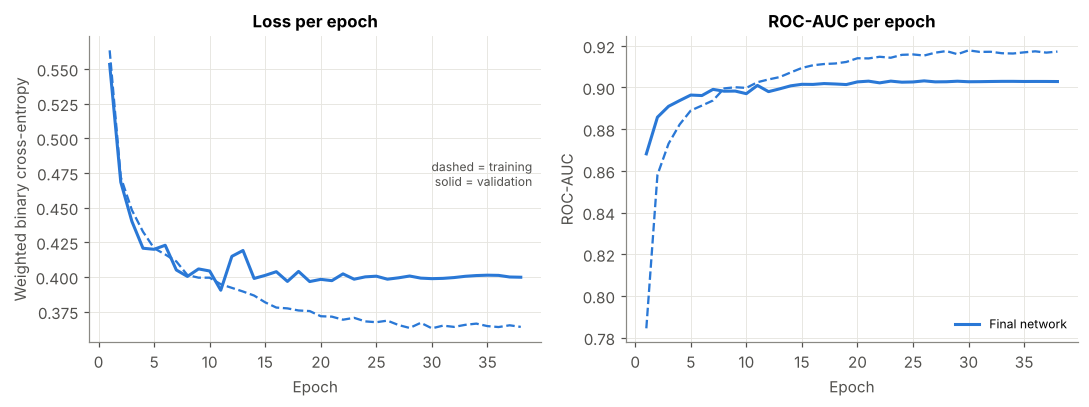

In [16]:
final = seed_runs[0]
final_model, final_hist = final["model"], final["history"]
plot_history({"Final network": final_hist}, FIG / "16_dl_final_training_curves.png")


When the same network was trained using five different random seeds, its validation ROC-AUC averaged 0.9012 ± 0.0014, with scores ranging from 0.8996 to 0.9032. This shows that small differences of around 0.003 may simply come from randomness rather than real improvements. The biggest changes came from preventing overfitting, which raised ROC-AUC from 0.869 to about 0.900, and using Adam instead of plain SGD, which improved it from 0.895 to around 0.900. Other changes, such as network size, dropout rate and random-search settings, made little difference. Batch normalisation improved the score by 0.0036, but this result is still borderline. Although the seed-42 run achieved the highest score of 0.9032, it was also the best-performing run by chance, so the average across all five runs gives a more reliable picture. During final training, early stopping selected the weights from epoch 26 out of 38. The training AUC was about 0.92, compared with 0.90 on validation data. This gap was much smaller than the unprotected network's 0.99 versus 0.87, suggesting that dropout, batch normalisation and early stopping helped control overfitting.

### 8c. Learning curve: does more data help the network?
As in notebook 2, we retrain the final configuration on 10%–100% of the training plots, **sampled by farmer** to keep the grouping, and evaluate on the fixed validation set.

 10% of farmers ->  2,296 plots | train 0.9565 | val 0.8733


 25% of farmers ->  5,752 plots | train 0.9418 | val 0.8888


 50% of farmers -> 11,405 plots | train 0.9239 | val 0.8926


 75% of farmers -> 17,348 plots | train 0.9284 | val 0.8990


100% of farmers -> 23,127 plots | train 0.9296 | val 0.9032


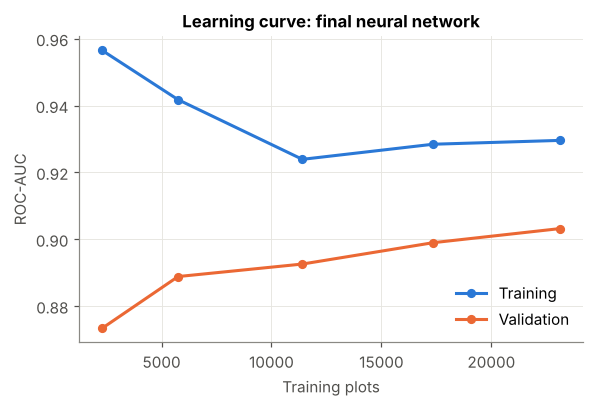

In [17]:
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
farmers = train["farmer_id"].unique()
lc_rows = []
for f in fracs:
    keep = set(np.random.default_rng(SEED).choice(farmers, int(len(farmers) * f), replace=False))
    m_ = train["farmer_id"].isin(keep).values
    Xt = {k: v[m_] for k, v in D_tr.items()} if FINAL_IS_EMB else X_tr[m_]
    Xv = D_va if FINAL_IS_EMB else X_va
    mdl, h, info = train_model(FINAL_CFG, build=FINAL_BUILD, data=(Xt, y_tr[m_], Xv, y_va))
    p_tr = mdl.predict(make_dataset(Xt, batch_size=4096), verbose=0).ravel()
    lc_rows.append({"n_train": int(m_.sum()), "train_auc": roc_auc_score(y_tr[m_], p_tr), "val_auc": info["val_roc_auc"]})
    print(f"{f:>4.0%} of farmers -> {m_.sum():>6,} plots | train {lc_rows[-1]['train_auc']:.4f} | val {info['val_roc_auc']:.4f}")
lc = pd.DataFrame(lc_rows)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
plot_learning_curve(lc["n_train"].values, lc[["train_auc"]].values, lc[["val_auc"]].values,
                    "Learning curve: final neural network", ax, val_label="Validation")
plt.tight_layout(); plt.savefig(FIG / "17_dl_learning_curve.png", bbox_inches="tight"); plt.show()

> As the network was trained on more data, the difference between its training and validation ROC-AUC became smaller, dropping from 0.084 with 10% of the farmers to 0.027 with the full dataset. This suggests that the network performed better on unseen data when it had more examples to learn from. At full size, its gap was also smaller than Gradient Boosting’s (0.027 compared with 0.067), meaning it was less prone to overfitting. The validation score was still improving near the end, rising from 0.893 to 0.899 and then 0.903, so using data from additional survey years might improve performance further. Interestingly, the network performed well even with limited data, reaching 0.873 with only 10% of the sample, compared with around 0.851 for Gradient Boosting. One possible reason is that regularisation helped the network learn patterns without simply memorising the training data. Since this dataset contains structured tables rather than images or text, the network may also be able to learn useful patterns from fewer examples. However, the comparison is not perfectly equal because Gradient Boosting was evaluated using cross-validation, while the network used a fixed validation set. Therefore, the overall trends are useful to compare, but the exact scores should be interpreted with caution.

### 9. Final test-set evaluation
The decision threshold is chosen on the **validation** set (maximum F1), exactly as for the traditional model, then applied to the test set.

In [18]:
Xva_f = D_va if FINAL_IS_EMB else X_va
Xte_f = D_te if FINAL_IS_EMB else X_te
p_va = final_model.predict(make_dataset(Xva_f, batch_size=4096), verbose=0).ravel()
thr_dl, _ = best_f1_threshold(y_va, p_va)
t0 = time.time()
p_te_dl = final_model.predict(make_dataset(Xte_f, batch_size=4096), verbose=0).ravel()
infer_ms_dl = (time.time() - t0) / len(y_te) * 1000
pred_te_dl = (p_te_dl >= thr_dl).astype(int)
dl_test = metrics(y_te, p_te_dl, pred_te_dl)
print(f"Validation-tuned threshold: {thr_dl:.3f}")
print({k: round(v, 4) for k, v in dl_test.items()})
print(classification_report(y_te, pred_te_dl, target_names=["No fertilizer", "Fertilizer"], digits=3))

Validation-tuned threshold: 0.671
{'roc_auc': 0.8969, 'pr_auc': 0.7677, 'f1': 0.7159, 'precision': 0.7033, 'recall': 0.729, 'accuracy': 0.84, 'balanced_acc': 0.8057}
               precision    recall  f1-score   support

No fertilizer      0.895     0.882     0.889      3650
   Fertilizer      0.703     0.729     0.716      1395

     accuracy                          0.840      5045
    macro avg      0.799     0.806     0.802      5045
 weighted avg      0.842     0.840     0.841      5045



### 10. Traditional ML vs deep learning
We load the saved Gradient Boosting pipeline from notebook 2 and score it on the **same test plots**.

To judge whether the ROC-AUC difference is real, we use a **paired bootstrap**: resample the 5,045 test plots with replacement 2,000 times, recompute both models' AUC on each resample, and take the 2.5th–97.5th percentiles of the difference. If the 95% interval contains 0, the two models are statistically indistinguishable on this test set.

In [19]:
ml = joblib.load(MODELS / "best_traditional_ml.joblib")
ml_pipe, thr_ml, ml_name = ml["pipeline"], ml["threshold"], ml["model_name"]
X_te_ml = test[ml["features"]["categorical"] + ml["features"]["numeric"] + ml["features"]["binary"]]
t0 = time.time(); p_te_ml = ml_pipe.predict_proba(X_te_ml)[:, 1]; infer_ms_ml = (time.time() - t0) / len(y_te) * 1000
pred_te_ml = (p_te_ml >= thr_ml).astype(int)
ml_test = metrics(y_te, p_te_ml, pred_te_ml)

from sklearn.base import clone
t0 = time.time(); clone(ml_pipe).fit(train[X_te_ml.columns], y_tr.astype(int)); ml_train_s = time.time() - t0   # time one refit
final_model.save(MODELS / "best_deep_learning.keras")
dl_name = "Neural network (" + ("Functional, embeddings" if FINAL_IS_EMB else "Sequential MLP") + ")"
size_mb = lambda p: p.stat().st_size / 1e6
comparison = pd.DataFrame({
    f"{ml_name} (traditional ML)": {**ml_test, "threshold": thr_ml, "training seconds": ml_train_s,
                                    "inference ms / plot": infer_ms_ml, "model file MB": size_mb(MODELS / "best_traditional_ml.joblib")},
    dl_name + " (deep learning)": {**dl_test, "threshold": thr_dl, "training seconds": final["train_seconds"],
                                   "inference ms / plot": infer_ms_dl, "model file MB": size_mb(MODELS / "best_deep_learning.keras")},
}).T
comparison.round(4)

,roc_auc,pr_auc,f1,precision,recall,accuracy,balanced_acc,threshold,training seconds,inference ms / plot,model file MB
Gradient Boosting (HGB) (traditional ML),0.8916,0.7658,0.7124,0.6774,0.7513,0.8323,0.8073,0.5716,5.2073,0.0208,2.4124
Neural network (Sequential MLP) (deep learning),0.8969,0.7677,0.7159,0.7033,0.7290,0.8400,0.8057,0.6710,15.9251,0.0046,0.2914


In [20]:
rng = np.random.default_rng(SEED); B = 2000; n = len(y_te); diffs = []
for _ in range(B):
    i = rng.integers(0, n, n)
    if y_te[i].min() == y_te[i].max(): continue
    diffs.append(roc_auc_score(y_te[i], p_te_dl[i]) - roc_auc_score(y_te[i], p_te_ml[i]))
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
obs = dl_test["roc_auc"] - ml_test["roc_auc"]
print(f"ROC-AUC difference (DL − ML): {obs:+.4f}   95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]")
print("→ statistically significant at 5%" if (lo > 0 or hi < 0) else "→ NOT significant: the interval includes 0")

ROC-AUC difference (DL − ML): +0.0052   95% bootstrap CI [+0.0016, +0.0087]
→ statistically significant at 5%


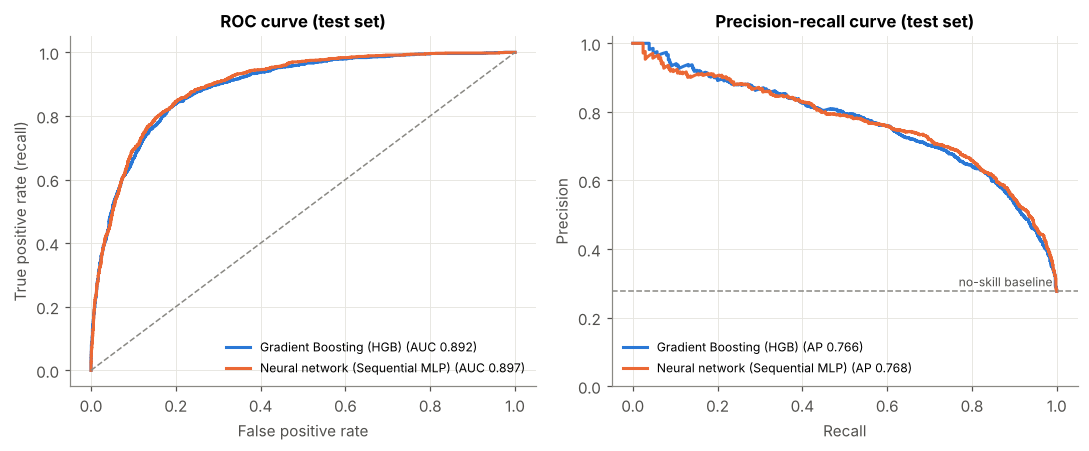

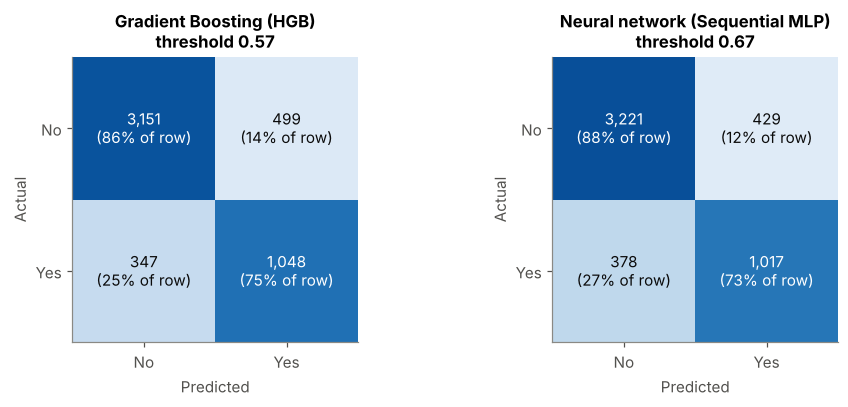

In [21]:
plot_roc_pr({ml_name: p_te_ml, dl_name: p_te_dl}, y_te, title_suffix=" (test set)", fname=FIG / "18_ml_vs_dl_roc_pr.png")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
plot_confusion(y_te, pred_te_ml, f"{ml_name}\nthreshold {thr_ml:.2f}", axes[0])
plot_confusion(y_te, pred_te_dl, f"{dl_name}\nthreshold {thr_dl:.2f}", axes[1])
plt.tight_layout(); plt.savefig(FIG / "19_ml_vs_dl_confusion.png", bbox_inches="tight"); plt.show()

#### 10a. Do the two models make the *same* mistakes?
If both models fail on the same plots, the limitation is probably **in the data**: those plots look like non-users on every recorded variable. If they fail on different plots, combining them could help.

In [22]:
ok_ml, ok_dl = pred_te_ml == y_te, pred_te_dl == y_te
agree = pd.Series({"both correct": (ok_ml & ok_dl).sum(), "only traditional ML correct": (ok_ml & ~ok_dl).sum(),
                   "only deep learning correct": (~ok_ml & ok_dl).sum(), "both wrong": (~ok_ml & ~ok_dl).sum()})
print(agree.to_string(), f"\n\nPrediction agreement: {(pred_te_ml == pred_te_dl).mean():.1%}",
      f"| score correlation: {np.corrcoef(p_te_ml, p_te_dl)[0, 1]:.3f}")

p_avg = (p_te_ml + p_te_dl) / 2
print(f"\nSimple average of both models: test ROC-AUC {roc_auc_score(y_te, p_avg):.4f} "
      f"(ML {ml_test['roc_auc']:.4f}, DL {dl_test['roc_auc']:.4f})  [exploratory only: not used for model selection]")

both_wrong = test.loc[~ok_ml & ~ok_dl].assign(actual=y_te[~ok_ml & ~ok_dl])
print("\nPlots both models got wrong, by actual class:", both_wrong["actual"].map({0: "No", 1: "Yes"}).value_counts().to_dict())
print(both_wrong.groupby("province").size().div(test.groupby("province").size()).round(3).rename("share of province's test plots").to_string())

both correct                   4073
only traditional ML correct     126
only deep learning correct      165
both wrong                      681 

Prediction agreement: 94.2% | score correlation: 0.961

Simple average of both models: test ROC-AUC 0.8975 (ML 0.8916, DL 0.8969)  [exploratory only: not used for model selection]

Plots both models got wrong, by actual class: {'No': 381, 'Yes': 300}
province
East      0.144
Kigali    0.105
North     0.162
South     0.091
West      0.168


> The neural network achieved a test ROC-AUC of 0.897, slightly below its validation score of 0.903. This is normal because selecting the best result from about 40 runs can make the validation score look better than the model’s actual performance. The average validation score across different seeds, 0.901, gives a more balanced estimate. Compared with Gradient Boosting, the network had a slightly higher ROC-AUC (0.897 vs 0.892) and precision (0.70 vs 0.68), while Gradient Boosting had better recall (0.75 vs 0.73). The network produced fewer false alarms (429 vs 499), but it also missed more fertilizer users (378 vs 347). A paired bootstrap test found that the network’s ROC-AUC advantage was statistically significant (95% CI: 0.002–0.009), although the improvement was small.
In practice, Gradient Boosting is faster to train, requires less tuning and is easier to explain using feature importance. The neural network is smaller and faster at prediction, but both models make predictions almost instantly. They agreed on 94% of test plots and made mistakes on the same 681 plots. This suggests that some cases are difficult to predict using the available data, possibly because important factors such as fertilizer prices, access to credit, distance to agro-dealers and soil quality were not recorded.
For MINAGRI or RAB, I would recommend Gradient Boosting for targeting agricultural extension services. Its performance is close to that of the neural network, but it is easier to maintain and explain to decision-makers. However, if the main goal is to reduce false alarms and avoid unnecessary extension visits, the neural network

### 11. Save the model and results
- **`best_deep_learning.keras`**: the native Keras format (architecture, weights, optimiser state). Load it with `keras.models.load_model(...)`.
- **`best_deep_learning.h5`**: the legacy HDF5 format, also saved because the assignment mentions `.h5`. For the embedding model, HDF5 cannot store the `StringLookup` vocabularies, so the `.keras` file is the one to use.
- **`dl_preprocessor.joblib`**: the fitted `ColumnTransformer`. The network expects inputs transformed by it.

Upload the model files to your **Google Drive** folder. All of them are gitignored.

In [23]:
final_model.save(MODELS / "best_deep_learning.keras")
try:
    final_model.save(MODELS / "best_deep_learning.h5")
except Exception as e:
    print("HDF5 export skipped:", type(e).__name__, "(use the .keras file)")
joblib.dump({"preprocessor": pre_other if FINAL_IS_EMB else pre, "threshold": thr_dl, "config": FINAL_CFG,
             "uses_embeddings": FINAL_IS_EMB, "feature_columns": (OTHER_CAT if FINAL_IS_EMB else CAT) + NUM + BIN},
            MODELS / "dl_preprocessor.joblib")

# reload check: the saved model must reproduce the same predictions
reloaded = keras.models.load_model(MODELS / "best_deep_learning.keras")
p_check = reloaded.predict(make_dataset(Xte_f, batch_size=4096), verbose=0).ravel()
print("Reloaded model reproduces predictions:", np.allclose(p_check, p_te_dl, atol=1e-5))

pd.DataFrame(LOG).to_csv(RESULTS / "dl_experiment_log.csv", index=False)
comparison.to_csv(RESULTS / "final_ml_vs_dl_comparison.csv")
json.dump({"final_config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in FINAL_CFG.items()},
           "uses_embeddings": FINAL_IS_EMB, "threshold": thr_dl, "test_metrics": dl_test,
           "seed_val_auc": aucs.tolist(), "bootstrap_auc_diff_dl_minus_ml": {"observed": obs, "ci95": [lo, hi]}},
          open(RESULTS / "deep_learning_results.json", "w"), indent=2, default=float)
for p in sorted(MODELS.iterdir()): print(f"  {p.name:32s} {size_mb(p):6.2f} MB")

Reloaded model reproduces predictions: True
  best_deep_learning.h5              0.30 MB
  best_deep_learning.keras           0.29 MB
  best_traditional_ml.joblib         2.41 MB
  dl_preprocessor.joblib             0.01 MB


### Summary
> **Deep Learning Experiments**
> 
>I started by testing a network without dropout or early stopping to see what would happen. It reached a training AUC of 0.99 but only 0.869 on validation, showing clear overfitting. Adding regularisation improved validation AUC to around 0.900. After that, changing the network size, dropout rate or L2 penalty made little difference, with scores between 0.896 and 0.900. Adam performed better than plain SGD (0.900 vs 0.895), while batch normalisation gave the highest score of 0.9032. A random search across 15 combinations did not improve this result. Using learned district embeddings also performed slightly worse than one-hot encoding (about 0.897), possibly because the dataset contains only 30 districts. When I trained the best network with five different random seeds, the average validation AUC was 0.9012 ± 0.0014, suggesting that most small differences between experiments came from randomness.
> 
**Final Network**
> 
>The selected network used 128 and 64 units, dropout of 0.3, batch normalisation and Adam. On the test set, it achieved a ROC-AUC of 0.897, an F1-score of 0.716, precision of 0.70 and recall of 0.73, using a decision threshold of 0.67 selected on validation data. The training AUC was about 0.92, compared with 0.90 on validation, showing that overfitting was relatively limited. The learning curve was still improving slowly, so adding survey data from other years could help the model perform better.
> 
**Comparison, Recommendation and Limitations**
> 
>The neural network achieved a ROC-AUC 0.005 higher than Gradient Boosting. Although a paired bootstrap test found this difference statistically significant (95% CI: 0.002–0.009), the practical improvement was small. Both models agreed on 94% of test plots and misclassified the same 681 plots, suggesting that missing information is a bigger problem than the choice of algorithm. I would recommend Gradient Boosting for MINAGRI or RAB because its performance is very close to the neural network's, while it is easier to train, maintain and explain. The main limitations are that the data covers only one survey year, relies on farmers' self-reported answers and excludes important factors such as fertilizer prices, soil quality, rainfall and access to credit. Therefore, the results show relationships in the data, not proof that these factors cause fertilizer use.